# 04 – Class imbalance experiments

All experiments use the residual 1D CNN (best model on validation in notebook 03) with the same training settings. Only the way the class imbalance is handled changes. Every change is applied to the **training split only**; the validation split is left untouched.

| Experiment | Description |
|---|---|
| A | No imbalance handling (reference) |
| B | Class weights in the loss |
| C | Oversampling of the minority classes |
| D | Best of B / C + data augmentation |

In [1]:
import os
import sys
import json
sys.path.append("..")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import RandomOverSampler

from src.data import load_mitbih, split_train_val, CLASS_NAMES, SEED
from src.models import build_resnet_cnn
from src.train import set_seed, train_model
from src.evaluate import (compute_metrics, per_class_table, summary_row, save_results,
                          plot_confusion_matrix, plot_history, FIG_DIR, METRICS_DIR, RESULTS_DIR)

MODEL_DIR = RESULTS_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.titlesize": 13, "axes.labelsize": 12})

In [2]:
X_train, y_train = load_mitbih("train")
X_tr, X_val, y_tr, y_val = split_train_val(X_train, y_train)
print("Train:", X_tr.shape, " Validation:", X_val.shape)

results = {}

Train: (70043, 187)  Validation: (17511, 187)


## A. No imbalance handling (reference)

This is the residual CNN trained in notebook 03 with exactly the same data, settings and seed. Training is deterministic, so its saved result is reused instead of training it again.

In [3]:
with open(METRICS_DIR / "resnet_cnn.json") as f:
    results["A_none"] = json.load(f)["metrics"]

print(f"Validation macro F1: {results['A_none']['macro_f1']:.3f}")
per_class_table(results["A_none"]).round(3)

Validation macro F1: 0.933


,precision,recall,f1,support
N,0.994,0.995,0.994,14494.0
S,0.902,0.872,0.887,445.0
V,0.963,0.979,0.971,1158.0
F,0.890,0.758,0.819,128.0
Q,0.995,0.995,0.995,1286.0


## B. Class weights

Each training sample's loss is multiplied by the weight of its class, so a mistake on a rare class costs more. The weights are the scikit-learn "balanced" weights computed on the training split: w_c = n_samples / (n_classes · n_c).

In [4]:
weights = compute_class_weight("balanced", classes=np.arange(len(CLASS_NAMES)), y=y_tr)
class_weight = {i: float(w) for i, w in enumerate(weights)}

pd.DataFrame({"train_count": np.bincount(y_tr), "weight": weights.round(2)}, index=CLASS_NAMES)

,train_count,weight
N,57977,0.24
S,1778,7.88
V,4630,3.03
F,513,27.31
Q,5145,2.72


In [5]:
set_seed(SEED)
model_b = build_resnet_cnn()
history, train_time = train_model(model_b, X_tr, y_tr, X_val, y_val, class_weight=class_weight)
print(f"Training time: {train_time:.0f} s")

Epoch 1/50


548/548 - 13s - 24ms/step - accuracy: 0.6715 - loss: 0.6421 - val_accuracy: 0.9103 - val_loss: 0.2814 - val_macro_f1: 0.6996 - learning_rate: 0.0010


Epoch 2/50


548/548 - 10s - 19ms/step - accuracy: 0.8171 - loss: 0.3877 - val_accuracy: 0.9146 - val_loss: 0.2561 - val_macro_f1: 0.7217 - learning_rate: 0.0010


Epoch 3/50


...

Epoch 48/50


548/548 - 11s - 20ms/step - accuracy: 0.9978 - loss: 0.0037 - val_accuracy: 0.9842 - val_loss: 0.0967 - val_macro_f1: 0.9144 - learning_rate: 7.8125e-06


Epoch 49/50


548/548 - 10s - 18ms/step - accuracy: 0.9979 - loss: 0.0036 - val_accuracy: 0.9844 - val_loss: 0.0970 - val_macro_f1: 0.9154 - learning_rate: 7.8125e-06


Training time: 524 s


In [6]:
y_pred = model_b.predict(X_val, batch_size=1024, verbose=0).argmax(axis=1)
metrics = compute_metrics(y_val, y_pred)
params = {"model": "ResNetCNN", "experiment": "B", "imbalance": "class_weight (balanced)",
          "class_weight": {CLASS_NAMES[i]: round(w, 3) for i, w in class_weight.items()},
          "lr": 1e-3, "batch_size": 128, "max_epochs": 50,
          "epochs_trained": len(history.history["loss"]), "seed": SEED,
          "train_time_s": round(train_time, 1)}
save_results("exp_B_class_weight", metrics, params, history.history)
model_b.save(MODEL_DIR / "exp_B_class_weight.keras")
results["B_class_weight"] = metrics

print(f"Validation macro F1: {metrics['macro_f1']:.3f}")
per_class_table(metrics).round(3)

Validation macro F1: 0.917


,precision,recall,f1,support
N,0.993,0.990,0.991,14494.0
S,0.840,0.872,0.856,445.0
V,0.963,0.968,0.966,1158.0
F,0.730,0.844,0.783,128.0
Q,0.987,0.989,0.988,1286.0


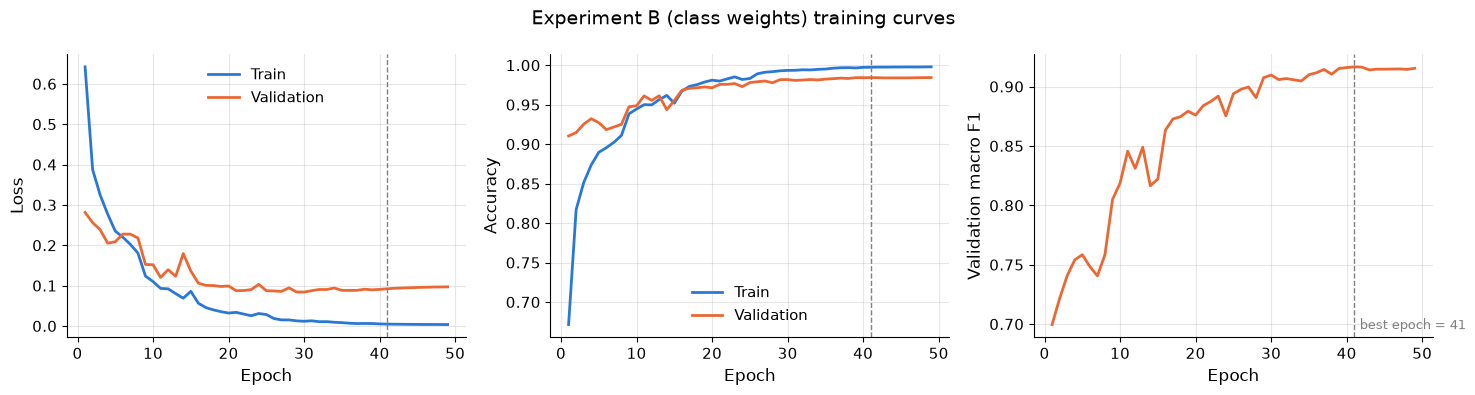

In [7]:
fig = plot_history(history.history, "Experiment B (class weights) training curves")
fig.savefig(FIG_DIR / "history_exp_B.png", dpi=200)
plt.show()

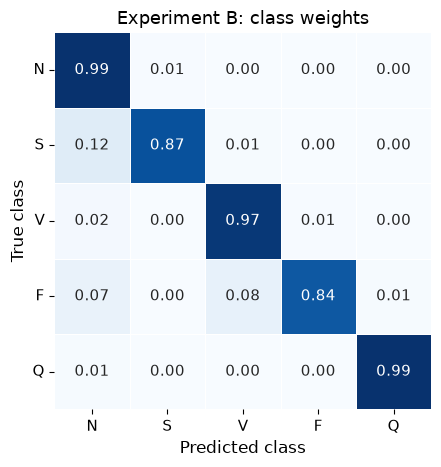

In [8]:
fig, ax = plt.subplots(figsize=(5, 4.8))
plot_confusion_matrix(y_val, y_pred, "Experiment B: class weights", ax=ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "cm_exp_B.png", dpi=200)
plt.show()

## C. Oversampling

Random oversampling: beats of every minority class are duplicated (sampled with replacement) until each class has as many training beats as N. Only the training split is resampled. No class weights are used. One epoch now covers about 290k beats instead of 70k, so each epoch takes roughly four times longer.

In [9]:
X_os, y_os = RandomOverSampler(random_state=SEED).fit_resample(X_tr, y_tr)

pd.DataFrame({"before": np.bincount(y_tr), "after": np.bincount(y_os)}, index=CLASS_NAMES)

,before,after
N,57977,57977
S,1778,57977
V,4630,57977
F,513,57977
Q,5145,57977


In [10]:
set_seed(SEED)
model_c = build_resnet_cnn()
history, train_time = train_model(model_c, X_os, y_os, X_val, y_val)
print(f"Training time: {train_time:.0f} s")

Epoch 1/50


2265/2265 - 39s - 17ms/step - accuracy: 0.9247 - loss: 0.2120 - val_accuracy: 0.9627 - val_loss: 0.1141 - val_macro_f1: 0.8521 - learning_rate: 0.0010


Epoch 2/50


2265/2265 - 37s - 16ms/step - accuracy: 0.9778 - loss: 0.0665 - val_accuracy: 0.9556 - val_loss: 0.1492 - val_macro_f1: 0.8485 - learning_rate: 0.0010


Epoch 3/50


...

Epoch 27/50


2265/2265 - 29s - 13ms/step - accuracy: 1.0000 - loss: 2.4214e-05 - val_accuracy: 0.9889 - val_loss: 0.1556 - val_macro_f1: 0.9342 - learning_rate: 6.2500e-05


Epoch 28/50


2265/2265 - 30s - 13ms/step - accuracy: 1.0000 - loss: 1.1022e-05 - val_accuracy: 0.9885 - val_loss: 0.1594 - val_macro_f1: 0.9330 - learning_rate: 3.1250e-05


Training time: 945 s


In [11]:
y_pred = model_c.predict(X_val, batch_size=1024, verbose=0).argmax(axis=1)
metrics = compute_metrics(y_val, y_pred)
params = {"model": "ResNetCNN", "experiment": "C", "imbalance": "random oversampling (all classes to N count)",
          "train_size_after": int(len(y_os)), "class_weight": None,
          "lr": 1e-3, "batch_size": 128, "max_epochs": 50,
          "epochs_trained": len(history.history["loss"]), "seed": SEED,
          "train_time_s": round(train_time, 1)}
save_results("exp_C_oversampling", metrics, params, history.history)
model_c.save(MODEL_DIR / "exp_C_oversampling.keras")
results["C_oversampling"] = metrics

print(f"Validation macro F1: {metrics['macro_f1']:.3f}")
per_class_table(metrics).round(3)

Validation macro F1: 0.936


,precision,recall,f1,support
N,0.993,0.995,0.994,14494.0
S,0.917,0.874,0.895,445.0
V,0.968,0.968,0.968,1158.0
F,0.828,0.828,0.828,128.0
Q,0.998,0.991,0.995,1286.0


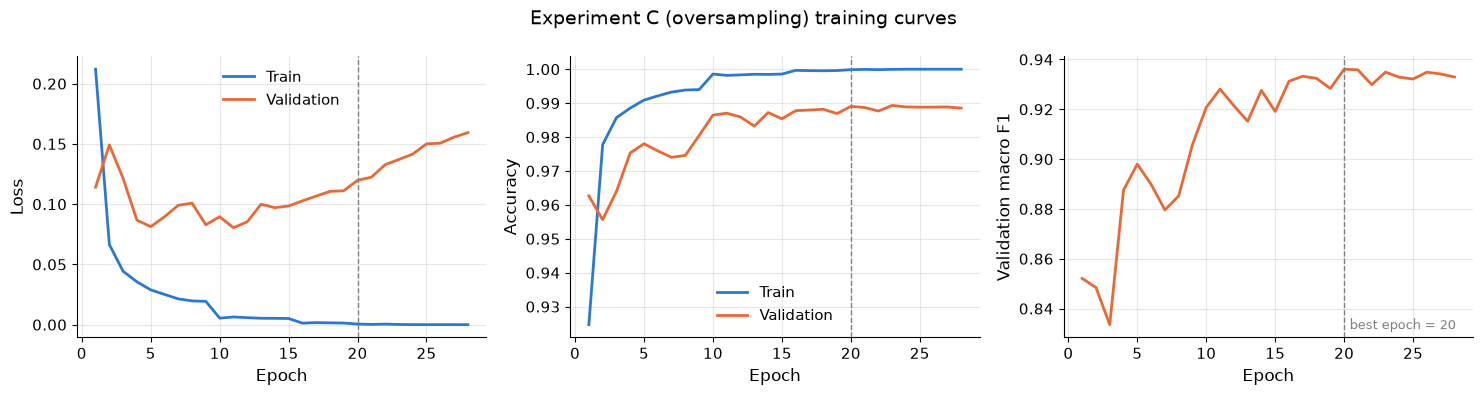

In [12]:
fig = plot_history(history.history, "Experiment C (oversampling) training curves")
fig.savefig(FIG_DIR / "history_exp_C.png", dpi=200)
plt.show()

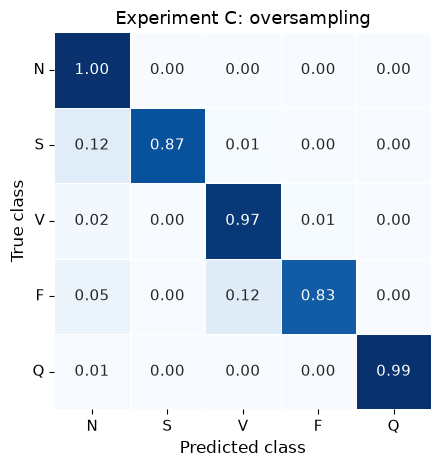

In [13]:
fig, ax = plt.subplots(figsize=(5, 4.8))
plot_confusion_matrix(y_val, y_pred, "Experiment C: oversampling", ax=ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "cm_exp_C.png", dpi=200)
plt.show()

## D. Oversampling + data augmentation

Oversampling (C) gave a better macro F1 than class weights (B), so it is combined with augmentation. The duplicated minority beats are the ones most at risk of being memorized; augmentation makes every copy slightly different. Each training batch is augmented on the fly, with new random values in every epoch. Each of the three transforms is applied independently with probability 0.5:

- **Time shift:** up to ±5 samples. The beat is shifted inside its own length (edge value fills the gap) so the trailing zero padding stays in place.
- **Amplitude scaling:** multiply by a random factor in [0.9, 1.1].
- **Gaussian noise:** σ = 0.02, added only to the beat part, not to the zero padding.

The validation set is not augmented.

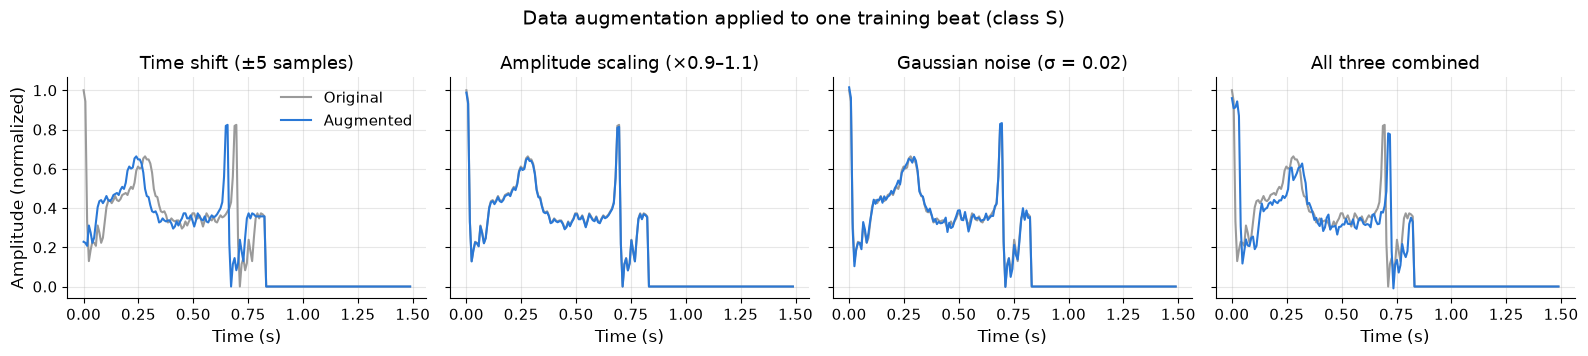

In [14]:
from src.augment import time_shift, scale_amplitude, add_noise, augment_batch

rng = np.random.default_rng(SEED)
beat = X_tr[np.flatnonzero(y_tr == 1)[0]][None, :]  # one S beat
t = np.arange(beat.shape[1]) / 125
examples = [
    ("Time shift (±5 samples)", time_shift(beat, rng)),
    ("Amplitude scaling (×0.9–1.1)", scale_amplitude(beat, rng)),
    ("Gaussian noise (σ = 0.02)", add_noise(beat, rng)),
    ("All three combined", augment_batch(beat, rng, p=1.0)),
]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, (title, aug) in zip(axes, examples):
    ax.plot(t, beat[0], color="#9a9a9a", linewidth=1.5, label="Original")
    ax.plot(t, aug[0], color="#2a78d6", linewidth=1.5, label="Augmented")
    ax.set_title(title)
    ax.set_xlabel("Time (s)")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Amplitude (normalized)")
axes[0].legend(frameon=False)
fig.suptitle("Data augmentation applied to one training beat (class S)", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "augmentation_examples.png", dpi=200)
plt.show()

In [15]:
augment = {"seed": SEED, "p": 0.5, "noise_std": 0.02, "scale": (0.9, 1.1), "max_shift": 5}

set_seed(SEED)
model_d = build_resnet_cnn()
history, train_time = train_model(model_d, X_os, y_os, X_val, y_val, augment=augment)
print(f"Training time: {train_time:.0f} s")

Epoch 1/50


2265/2265 - 41s - 18ms/step - accuracy: 0.8968 - loss: 0.2855 - val_accuracy: 0.9649 - val_loss: 0.1095 - val_macro_f1: 0.8414 - learning_rate: 0.0010


Epoch 2/50


2265/2265 - 38s - 17ms/step - accuracy: 0.9584 - loss: 0.1189 - val_accuracy: 0.9713 - val_loss: 0.0914 - val_macro_f1: 0.8657 - learning_rate: 0.0010


Epoch 3/50


...

Epoch 37/50


2265/2265 - 41s - 18ms/step - accuracy: 0.9982 - loss: 0.0056 - val_accuracy: 0.9875 - val_loss: 0.0821 - val_macro_f1: 0.9290 - learning_rate: 7.8125e-06


Epoch 38/50


2265/2265 - 39s - 17ms/step - accuracy: 0.9981 - loss: 0.0057 - val_accuracy: 0.9877 - val_loss: 0.0823 - val_macro_f1: 0.9303 - learning_rate: 7.8125e-06


Training time: 1446 s


In [16]:
y_pred = model_d.predict(X_val, batch_size=1024, verbose=0).argmax(axis=1)
metrics = compute_metrics(y_val, y_pred)
params = {"model": "ResNetCNN", "experiment": "D",
          "imbalance": "random oversampling (all classes to N count)", "augmentation": augment,
          "train_size_after": int(len(y_os)), "class_weight": None,
          "lr": 1e-3, "batch_size": 128, "max_epochs": 50,
          "epochs_trained": len(history.history["loss"]), "seed": SEED,
          "train_time_s": round(train_time, 1)}
save_results("exp_D_oversampling_aug", metrics, params, history.history)
model_d.save(MODEL_DIR / "exp_D_oversampling_aug.keras")
results["D_oversampling_aug"] = metrics

print(f"Validation macro F1: {metrics['macro_f1']:.3f}")
per_class_table(metrics).round(3)

Validation macro F1: 0.933


,precision,recall,f1,support
N,0.994,0.993,0.994,14494.0
S,0.891,0.885,0.888,445.0
V,0.957,0.972,0.964,1158.0
F,0.812,0.844,0.828,128.0
Q,0.997,0.990,0.993,1286.0


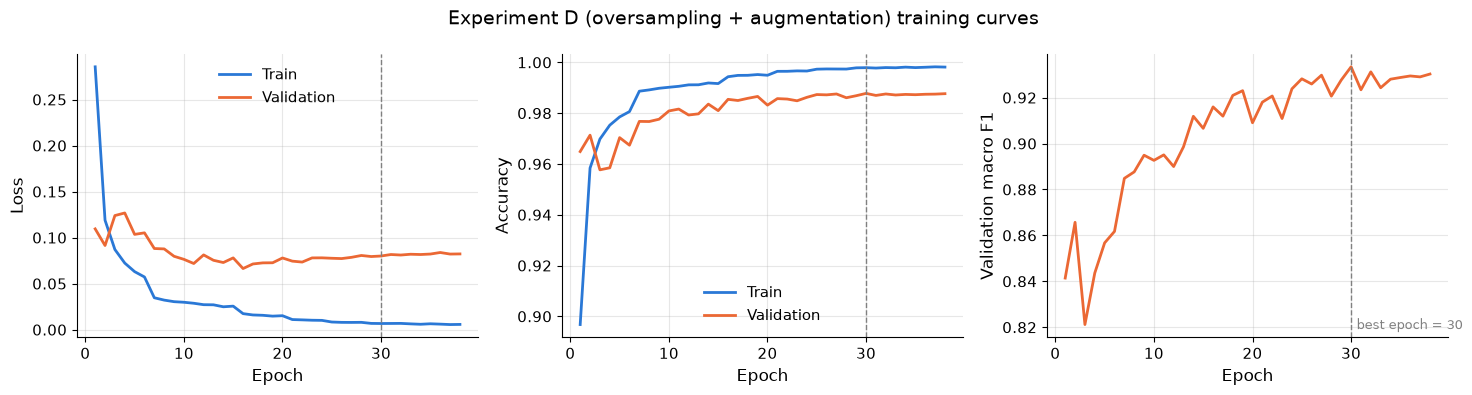

In [17]:
fig = plot_history(history.history, "Experiment D (oversampling + augmentation) training curves")
fig.savefig(FIG_DIR / "history_exp_D.png", dpi=200)
plt.show()

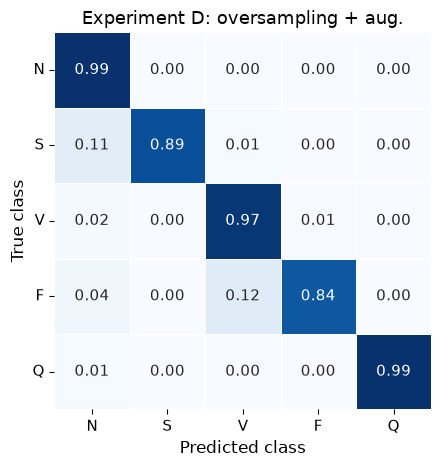

In [18]:
fig, ax = plt.subplots(figsize=(5, 4.8))
plot_confusion_matrix(y_val, y_pred, "Experiment D: oversampling + aug.", ax=ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "cm_exp_D.png", dpi=200)
plt.show()

## D2. Oversampling + augmentation without time shift

Every beat in this dataset starts at its R peak, so the first sample is always the peak. The time shift in D breaks this: a left shift cuts off the peak and a right shift adds a flat segment at the start. Neither ever occurs in real (validation or test) beats. D2 repeats D with only amplitude scaling and Gaussian noise.

In [19]:
augment = {"seed": SEED, "p": 0.5, "noise_std": 0.02, "scale": (0.9, 1.1), "max_shift": 0}

set_seed(SEED)
model_d2 = build_resnet_cnn()
history, train_time = train_model(model_d2, X_os, y_os, X_val, y_val, augment=augment)
print(f"Training time: {train_time:.0f} s")

Epoch 1/50


2265/2265 - 42s - 18ms/step - accuracy: 0.9223 - loss: 0.2172 - val_accuracy: 0.9451 - val_loss: 0.1647 - val_macro_f1: 0.8171 - learning_rate: 0.0010


Epoch 2/50


2265/2265 - 40s - 17ms/step - accuracy: 0.9763 - loss: 0.0708 - val_accuracy: 0.9654 - val_loss: 0.1078 - val_macro_f1: 0.8329 - learning_rate: 0.0010


Epoch 3/50


...

Epoch 43/50


2265/2265 - 26s - 12ms/step - accuracy: 0.9998 - loss: 5.8944e-04 - val_accuracy: 0.9886 - val_loss: 0.1197 - val_macro_f1: 0.9303 - learning_rate: 3.9063e-06


Epoch 44/50


2265/2265 - 27s - 12ms/step - accuracy: 0.9998 - loss: 6.7772e-04 - val_accuracy: 0.9885 - val_loss: 0.1201 - val_macro_f1: 0.9287 - learning_rate: 3.9063e-06


Training time: 1358 s


In [20]:
y_pred = model_d2.predict(X_val, batch_size=1024, verbose=0).argmax(axis=1)
metrics = compute_metrics(y_val, y_pred)
params = {"model": "ResNetCNN", "experiment": "D2",
          "imbalance": "random oversampling (all classes to N count)", "augmentation": augment,
          "train_size_after": int(len(y_os)), "class_weight": None,
          "lr": 1e-3, "batch_size": 128, "max_epochs": 50,
          "epochs_trained": len(history.history["loss"]), "seed": SEED,
          "train_time_s": round(train_time, 1)}
save_results("exp_D2_oversampling_aug_noshift", metrics, params, history.history)
model_d2.save(MODEL_DIR / "exp_D2_oversampling_aug_noshift.keras")
results["D2_oversampling_aug_noshift"] = metrics

print(f"Validation macro F1: {metrics['macro_f1']:.3f}")
per_class_table(metrics).round(3)

Validation macro F1: 0.932


,precision,recall,f1,support
N,0.994,0.995,0.995,14494.0
S,0.915,0.874,0.894,445.0
V,0.970,0.968,0.969,1158.0
F,0.806,0.812,0.809,128.0
Q,0.996,0.994,0.995,1286.0


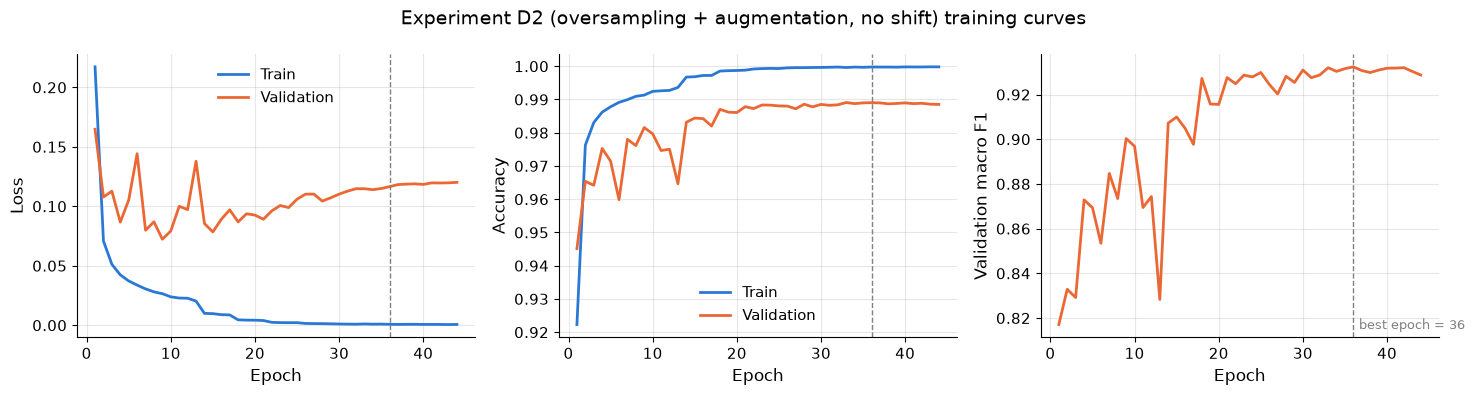

In [21]:
fig = plot_history(history.history, "Experiment D2 (oversampling + augmentation, no shift) training curves")
fig.savefig(FIG_DIR / "history_exp_D2.png", dpi=200)
plt.show()

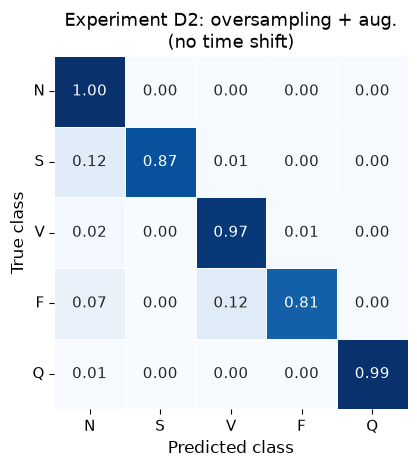

In [22]:
fig, ax = plt.subplots(figsize=(5, 4.8))
plot_confusion_matrix(y_val, y_pred, "Experiment D2: oversampling + aug.\n(no time shift)", ax=ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "cm_exp_D2.png", dpi=200)
plt.show()

## Comparison (validation set)

Selection rule (fixed before D2 was run): the configuration with the highest validation macro F1 is chosen. If the two best differ by less than 0.005, the difference is treated as noise from a single seed and the configuration with less overfitting (lower validation loss over the last epochs) is chosen.

In [23]:
comparison = pd.DataFrame([summary_row(name, m) for name, m in results.items()])
comparison["precision_S"] = [m["per_class"]["S"]["precision"] for m in results.values()]
comparison["precision_F"] = [m["per_class"]["F"]["precision"] for m in results.values()]
comparison.to_csv(METRICS_DIR / "imbalance_summary.csv", index=False)
comparison.round(3)

,model,accuracy,balanced_accuracy,macro_f1,recall_S,recall_V,recall_F,precision_S,precision_F
0,A_none,0.989,0.920,0.933,0.872,0.979,0.758,0.902,0.890
1,B_class_weight,0.984,0.933,0.917,0.872,0.968,0.844,0.840,0.730
2,C_oversampling,0.989,0.931,0.936,0.874,0.968,0.828,0.917,0.828
3,D_oversampling_aug,0.988,0.937,0.933,0.885,0.972,0.844,0.891,0.812
4,D2_oversampling_aug_noshift,0.989,0.929,0.932,0.874,0.968,0.812,0.915,0.806


## Selected configuration

The two best configurations by validation macro F1 are C (0.936) and D (0.933). They differ by 0.003, less than 0.005, so by the selection rule the one with less overfitting is chosen: **D (oversampling + augmentation with time shift)**. Its validation loss stays around 0.08 in the last epochs, while for C it rises to about 0.15.

D2 shows that the time shift was the part of the augmentation that reduced overfitting: without it, the validation loss rises again (about 0.12 in the last epochs) and macro F1 is slightly lower (0.932). Class weights (B) gave the lowest macro F1 because the precision of S and F dropped.